Comparison saved as: preprocessing_test_20260410_222002.png


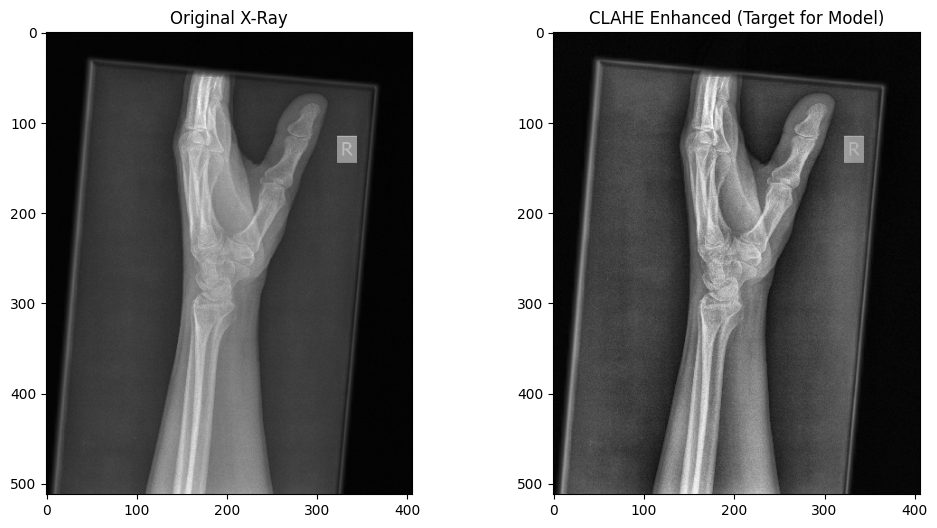

In [7]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# 1. Setup paths
BASE_DIR = '../'  # Points to project root from the notebooks folder
CSV_PATH = os.path.join(BASE_DIR, 'MURA-v1.1/train_image_paths.csv')

# 2. Load and filter for a sample
df = pd.read_csv(CSV_PATH, header=None, names=['image_path'])
hand_wrist_df = df[df['image_path'].str.contains('XR_HAND|XR_WRIST')]
sample_path = os.path.join(BASE_DIR, hand_wrist_df.sample(1).iloc[0]['image_path'])

# 3. Define the CLAHE function (matching your src/data_loader.py logic)
def preview_clahe(path, clip_limit=2.0, grid_size=(8, 8)):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=grid_size)
    enhanced = clahe.apply(img)
    return img, enhanced

# 4. Process and Visualize
original, enhanced = preview_clahe(sample_path)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Original X-Ray")
plt.imshow(original, cmap='gray')

plt.subplot(1, 2, 2)
plt.title("CLAHE Enhanced (Target for Model)")
plt.imshow(enhanced, cmap='gray')

# 5. Save the result to a new file every time for documentation
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
save_filename = f"preprocessing_test_{timestamp}.png"
plt.savefig(save_filename)
print(f"Comparison saved as: {save_filename}")

plt.show()